<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_inequality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spatial inequality of poverty and night-time lights

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

How unequal are Bolivia's 339 municipalities, and how much of that inequality is regional? This notebook measures inequality in two indicators for 2012:

- **Multidimensional poverty** (`sdg1_2_mpi`, Multidimensional Poverty Index, 0–1; **higher = poorer**)
- **Night-time lights per capita** (`ln_t400NTLpc`, the Hodrick–Prescott trend of log lights per person)

Outline:

1. **Load** the data with `geo4bolivia`
2. **Distributions** and maps
3. **Theil index**, decomposed between and within the 9 departments
4. **Gini coefficient**
5. **Spatial Gini**: how much inequality lies between neighbouring municipalities
6. **Summary**

## 0. Setup

In Google Colab the next cell installs what Colab lacks (a few seconds). Locally, `uv sync` has installed everything already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify", "libpysal", "inequality"]
           if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import geo4bolivia as geo
from libpysal import weights
import inequality
from inequality.gini import Gini_Spatial

import warnings
warnings.filterwarnings("ignore")

## 1. Load the data

Each municipality has one `geo_id` (e.g. `BO-04-17-04`, La Paz). Poverty comes from the SDG Atlas at its reference year (2012), lights from the `ntl` dataset in the same year. `geometry=True` attaches the boundaries; `geo.units()` gives each municipality its department.

In [3]:
mpi = geo.load("sdg01", variables="sdg1_2_mpi", years=2012, geometry=True)
ntl = geo.load("ntl", variables="ln_t400NTLpc", years=2012)
pop = geo.load("pop", years=2012)

units = geo.units("municipality")
departments = geo.units("department").set_index("geo_id")["name"]

gdf = (mpi.merge(ntl[["geo_id", "ln_t400NTLpc"]], on="geo_id")
          .merge(pop[["geo_id", "pop"]], on="geo_id")
          .merge(units[["geo_id", "department_id"]], on="geo_id"))
gdf["department"] = gdf["department_id"].map(departments)
gdf = gdf.to_crs(geo.config()["equal_area_crs"])     # metres, for maps and neighbours

print(gdf.shape, "| missing values:", int(gdf[["sdg1_2_mpi", "ln_t400NTLpc"]].isna().sum().sum()))
gdf[["geo_id", "name", "department", "sdg1_2_mpi", "ln_t400NTLpc", "pop"]].head()

(339, 9) | missing values: 0


,geo_id,name,department,sdg1_2_mpi,ln_t400NTLpc,pop
0,BO-01-01-01,Azurduy,Chuquisaca,0.440,11.048312,10927.5350
1,BO-01-01-02,Tarvita,Chuquisaca,0.380,12.329279,14207.9030
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.199,12.815315,11159.8340
3,BO-01-03-01,Huacareta,Chuquisaca,0.261,12.018971,8394.6611
4,BO-01-03-02,Monteagudo,Chuquisaca,0.166,14.603350,24266.3730


In [4]:
MPI = "sdg1_2_mpi"         # Multidimensional Poverty Index, 2012 (higher = poorer)
NTL = "ln_t400NTLpc"       # log night-time lights per capita, HP trend, 2012
GROUP = "department"       # 9 departments
labels = {MPI: "Multidimensional poverty index (2012)",
          NTL: "Log night-time lights per capita (2012)"}

## 2. Distributions and maps

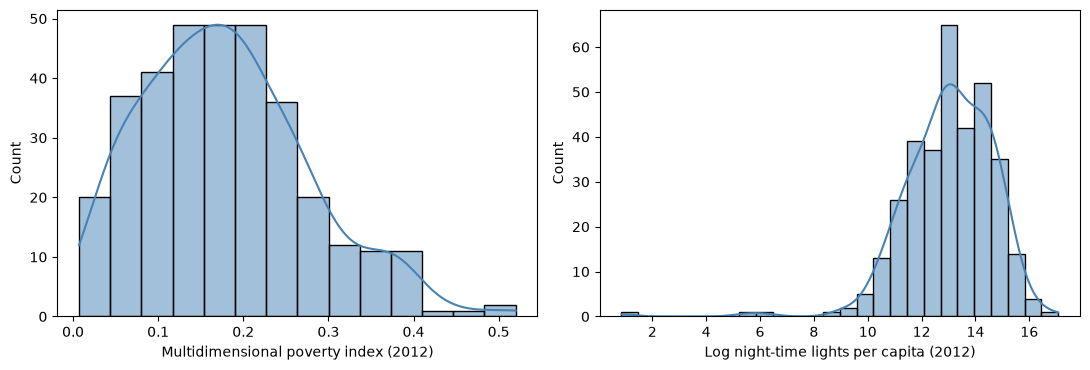

,sdg1_2_mpi,ln_t400NTLpc
count,339.000,339.000
mean,0.179,13.033
std,0.098,1.672
min,0.007,0.856
25%,0.105,12.050
50%,0.171,13.118
75%,0.241,14.268
max,0.520,17.071


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, var in zip(axes, [MPI, NTL]):
    sns.histplot(gdf[var], kde=True, ax=ax, color="steelblue")
    ax.set_xlabel(labels[var])
plt.tight_layout()
plt.show()

gdf[[MPI, NTL]].describe().round(3)

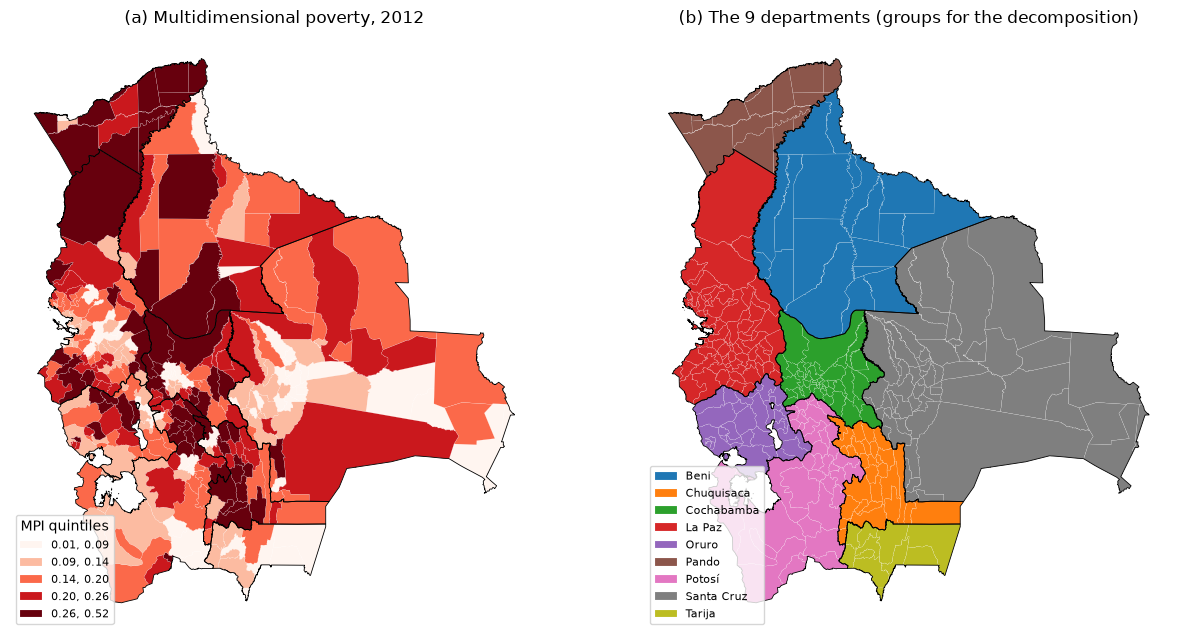

In [6]:
# department outlines
dep_lines = geo.boundaries("department").to_crs(gdf.crs).boundary

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
gdf.plot(column=MPI, scheme="Quantiles", k=5, cmap="Reds", linewidth=0.1, edgecolor="white",
         legend=True, legend_kwds={"loc": "lower left", "fontsize": 8, "title": "MPI quintiles"}, ax=axes[0])
axes[0].set_title("(a) Multidimensional poverty, 2012")
gdf.plot(column=GROUP, categorical=True, cmap="tab10", linewidth=0.1, edgecolor="white",
         legend=True, legend_kwds={"loc": "lower left", "fontsize": 8}, ax=axes[1])
axes[1].set_title("(b) The 9 departments (groups for the decomposition)")
for ax in axes:
    dep_lines.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

Poverty in 2012 averages 0.179 across municipalities and ranges from 0.007 to 0.520. The poorest quintile (MPI above 0.26) appears in two broad areas: the Andean valleys where northern Potosí, Chuquisaca and Cochabamba meet, and the Amazonian north (Pando, northern La Paz and parts of Beni). The least poor municipalities include the departmental capitals, most of Tarija and southeastern Santa Cruz. Log lights per capita are concentrated between 10 and 16, with a handful of very dark outliers (one below 2). Poverty is right-skewed: a tail of municipalities has an MPI above 0.3.

Before decomposing, the department averages show how large the regional gaps are. The population-weighted mean uses `geo.aggregate` with the `pop` dataset (2012) as weights:

In [7]:
dep_pw = geo.aggregate(gdf[["geo_id", "year", MPI]], to="department",
                       rules={MPI: "weighted_mean:pop"}, weights=pop)
dep_pw["department"] = dep_pw["geo_id"].map(departments)

dep_table = (gdf.groupby(GROUP)
               .agg(municipalities=(MPI, "size"), mean_mpi=(MPI, "mean"), mean_ln_ntl=(NTL, "mean"))
               .join(dep_pw.set_index("department")[MPI].rename("pop_weighted_mpi"))
               .sort_values("mean_mpi", ascending=False))
dep_table.round(3)

,municipalities,mean_mpi,mean_ln_ntl,pop_weighted_mpi
department,,,,
Pando,15,0.322,12.471,0.222
Chuquisaca,29,0.260,12.635,0.181
Potosí,40,0.204,12.469,0.166
Beni,19,0.196,12.113,0.158
Cochabamba,47,0.175,13.789,0.099
Oruro,35,0.172,13.209,0.094
La Paz,87,0.166,12.403,0.077
Santa Cruz,56,0.122,14.047,0.054
Tarija,11,0.082,14.509,0.052


## 3. Theil index

The Theil index is 0 under perfect equality and rises with inequality. Its key property is **additive decomposability**: with the municipalities grouped into departments, total inequality splits exactly into a *between-department* part (differences in department means) and a *within-department* part (differences among municipalities of the same department).

In [8]:
theil = {var: inequality.theil.Theil(gdf[var].values).T for var in [MPI, NTL]}
{var: round(float(t), 4) for var, t in theil.items()}

{'sdg1_2_mpi': 0.1535, 'ln_t400NTLpc': 0.0094}

In [9]:
rows = []
for var in [MPI, NTL]:
    d = inequality.theil.TheilD(gdf[var].values, gdf[GROUP].values)
    total, between, within = float(theil[var]), float(np.squeeze(d.bg)), float(np.squeeze(d.wg))
    rows.append({"variable": var, "Theil": total, "between": between, "within": within,
                 "between share": between / total, "within share": within / total})
theil_table = pd.DataFrame(rows).set_index("variable")
theil_table.round(4)

,Theil,between,within,between share,within share
variable,,,,,
sdg1_2_mpi,0.1535,0.0366,0.1169,0.2384,0.7616
ln_t400NTLpc,0.0094,0.0016,0.0079,0.1664,0.8336


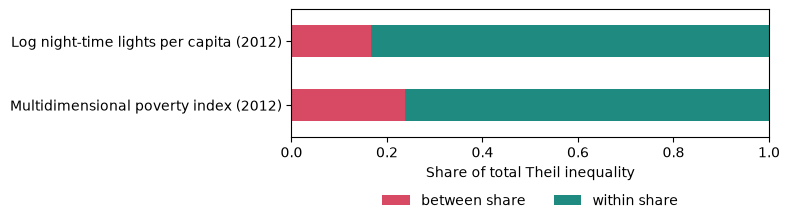

In [10]:
ax = theil_table[["between share", "within share"]].rename(index=labels).plot.barh(
    stacked=True, color=["#d84a64", "#1f8a80"], figsize=(8, 2.6))
ax.set_xlim(0, 1)
ax.set_xlabel("Share of total Theil inequality")
ax.set_ylabel("")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

The Theil index of poverty (0.154) is much larger than that of log lights (0.009). The two levels are not comparable: lights enter in logs, which compresses their dispersion by construction, while the MPI is a ratio-scale index. Only the **shares** of the decomposition are comparable.

For both indicators **most inequality is within departments**: 76% for poverty and 83% for lights. Differences between department averages explain 24% of poverty inequality and 17% of lights inequality. Bolivia's municipal disparities are therefore mostly local: each department contains both poor and less-poor municipalities. The department table above hints at one reason: in every department the population-weighted MPI is below the unweighted mean, so the populous municipalities, led by the capitals, are less poor than the small rural ones (in La Paz, 0.166 on average across municipalities against 0.077 per person).

## 4. Gini coefficient

The Gini coefficient (0 = equality, 1 = maximal inequality) is half the mean absolute difference between all pairs of municipalities, relative to the mean.

In [11]:
gini = {var: inequality.gini.Gini(gdf[var].values).g for var in [MPI, NTL]}
{var: round(float(g), 4) for var, g in gini.items()}

{'sdg1_2_mpi': 0.3057, 'ln_t400NTLpc': 0.0675}

The Gini of poverty is 0.306: the expected gap in MPI between two randomly drawn municipalities is about 61% of the mean MPI (twice the Gini). The Gini of log lights is 0.068, small for the same reason as its Theil index.

## 5. Spatial Gini

The spatial Gini (Rey and Smith, 2013) splits the Gini into the contribution of pairs of **neighbouring** municipalities and that of non-neighbours. If inequality had no spatial structure, neighbours would differ as much as any random pair, and their share of the Gini would roughly equal their share of all pairs. A smaller share means neighbours are more alike than random pairs (positive spatial autocorrelation). The p-value compares the observed split with 999 random reshufflings of the values across the map.

Neighbours are the 6 nearest municipalities (k-nearest neighbours on centroids in the equal-area projection), as in the original DS4Bolivia notebook. `Gini_Spatial` only uses who is a neighbour, so the weights stay binary.

In [12]:
W = weights.KNN.from_dataframe(gdf, k=6)      # binary: 1 for each of the 6 nearest neighbours
n = len(gdf)

np.random.seed(12345)
rows = []
for var in [MPI, NTL]:
    sg = Gini_Spatial(gdf[var].values, W, permutations=999)
    rows.append({"variable": var,
                 "Gini": sg.g,
                 "neighbour pairs, % of pairs": 100 * W.s0 / (n * (n - 1)),
                 "neighbour share of Gini, %": 100 * sg.wg / sg.dtotal,
                 "expected if random, %": 100 * (1 - sg.e_wcg / sg.dtotal),
                 "non-neighbour Gini (wcg_share)": sg.wcg_share,
                 "p-value": sg.p_sim})
spatial_gini = pd.DataFrame(rows).set_index("variable")
spatial_gini.round(4)

,Gini,"neighbour pairs, % of pairs","neighbour share of Gini, %","expected if random, %",non-neighbour Gini (wcg_share),p-value
variable,,,,,,
sdg1_2_mpi,0.3057,1.7751,1.2487,1.7732,0.3018,0.001
ln_t400NTLpc,0.0675,1.7751,1.3051,1.7749,0.0666,0.001


Pairs of neighbours are 1.78% of all pairs of municipalities, and under random reshuffling they would carry about the same share of the Gini (1.77%). In fact they carry only 1.25% of poverty inequality and 1.30% of lights inequality. The difference is significant for both (p = 0.001, the smallest value 999 permutations allow): **inequality is spatially structured**. Neighbours resemble each other, and almost all inequality (about 98.7% of the Gini) comes from pairs of municipalities that are not neighbours. The `wcg_share` column, which the original DS4Bolivia notebook printed, is this non-neighbour part in Gini units (0.302 of the 0.306 for poverty), not a share of neighbours.

## 6. Summary

In [13]:
summary = pd.DataFrame({
    "Theil": theil_table["Theil"],
    "Theil: between departments": theil_table["between share"],
    "Theil: within departments": theil_table["within share"],
    "Gini": pd.Series({v: float(g) for v, g in gini.items()}),
    "Spatial Gini: neighbour share, %": spatial_gini["neighbour share of Gini, %"],
    "Spatial Gini: p-value": spatial_gini["p-value"],
}).rename(index=labels)
summary.T.round(4)

,Multidimensional poverty index (2012),Log night-time lights per capita (2012)
Theil,0.1535,0.0094
Theil: between departments,0.2384,0.1664
Theil: within departments,0.7616,0.8336
Gini,0.3057,0.0675
"Spatial Gini: neighbour share, %",1.2487,1.3051
Spatial Gini: p-value,0.0010,0.0010


- Municipal **poverty is very unequal** (Gini 0.31, Theil 0.15). Lights, measured in logs, show low inequality on that scale.
- **Most inequality lies within departments**: 76% for poverty and 83% for lights. Departmental averages hide most of the disparities that matter for targeting.
- Inequality is **spatially structured**: neighbouring municipalities resemble each other, so the poor and the less-poor municipalities form regional clusters that cut across department boundaries.

Related notebooks: `esda_dependence` (Moran's I and LISA clusters) and `esda_heterogeneity` (GWR and MGWR of poverty on lights).